# Why attitudes moved in Study 2 but not Study 1

AIM reduced psychological distance by the same amount in both studies. Two things differed:
Study 1 is a more crystallized attitude domain, and AIM produced less narrative transportation
there. Slopes use the **control arms**, which contain nobody who used AIM, so they describe the
two issues before any intervention.

The LLM annotations and the Media Cloud counts are read from CSVs rather than re-fetched.

## Setup

In [1]:
"""
Author: Joshua Ashkinaze

Description: Why AIM changed policy attitudes in Study 2 but not Study 1. Two accounts:
Study 1 is a more crystallized attitude domain, and AIM produced less narrative
transportation there. Slopes use the control arms, which contain nobody who used AIM.

Inputs:
    - sci_fund_real/data/clean/analysis_data.csv: Study 1 (science funding)
    - satellite/data/clean/analysis_data.csv: Study 2 (satellite cybersecurity)
    - data/crystallization_annotations.csv: LLM crystallization labels (annotate_crystallization.py)
    - data/news_coverage.csv: Media Cloud story counts

Outputs:
    - tables/*.tex: one table per claim
    - plots/transportation_items.pdf: item-level treatment effects
"""

import sys, warnings
import numpy as np, pandas as pd, statsmodels.formula.api as smf
import pingouin as pg
from sklearn.utils import resample as bootstrap_sample
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest
from pathlib import Path
import sys
from pathlib import Path

current_dir = Path.cwd()

sys.path.extend(str(current_dir.parents[i]) for i in range(3))
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "helpers.py").exists())
HERE = ROOT / "explain_divergence"
TABLE_EXPORT = HERE / "tables"
FIGURE_EXPORT = HERE / "plots"
DATA = HERE / "data"
sys.path.insert(0, str(ROOT / "src"))
from helpers import make_aesthetic
warnings.filterwarnings("ignore")

s1 = pd.read_csv(ROOT / "sci_fund_real/data/clean/analysis_data.csv")
s2 = pd.read_csv(ROOT / "satellite/data/clean/analysis_data.csv")
for d in (s1, s2):
    d["treat"] = (d.treat_status == "treat").astype(float)
    d["ideo_dir"] = np.sign(d.ideology_num - 4)          # -1 liberal, +1 conservative
    d["ideo_str"] = (d.ideology_num - 4).abs()           # 0 to 3
STUDIES = {"Study 1": s1, "Study 2": s2}

def fit(data, formula, term):
    """OLS with HC1 errors; return the one coefficient we care about."""
    m = smf.ols(formula, data=data).fit(cov_type="HC1")
    lo, hi = m.conf_int().loc[term]
    return {"b": m.params[term], "lo": lo, "hi": hi, "p": m.pvalues[term], "n": int(m.nobs)}

def save(rows, stem, caption):
    df = pd.DataFrame(rows)
    df.to_latex(TABLE_EXPORT / f"{stem}.tex", index=False, float_format="%.3f",
                caption=caption, label=f"tab:{stem}", position="H")
    return df

def ci_str(b, lo, hi, digits=2):
    """Estimate with its 95% interval, for compact tables."""
    return f"{b:.{digits}f} [{lo:.{digits}f}, {hi:.{digits}f}]"

def p_str(p):
    """APA-style p value."""
    return "<.001" if p < .001 else f"{p:.3f}".lstrip("0")

print(f"Study 1 n={len(s1)}, Study 2 n={len(s2)}")

Study 1 n=1007, Study 2 n=894


## 1. Study 1 is the more crystallized domain

News salience, ideology, and participants' own reports of prior views.

In [2]:
###############
# 1. Study 1 is the more crystallized domain
###############

# News salience, from Media Cloud (fetched separately; see news_coverage.csv)
news = pd.read_csv(DATA / "news_coverage.csv")
print(news[news.scope == "narrow"].to_string(index=False))

# Ideology predicts attitudes in the control arms, before any treatment
rows = [dict(study=k, predictor=lab, **fit(d[d.treat_status != "treat"],
             "attitude_index ~ ideo_dir + ideo_str", term))
        for k, d in STUDIES.items()
        for term, lab in [("ideo_dir", "Ideological direction"), ("ideo_str", "Ideological strength")]]
print("\n", save(rows, "crystallization",
      "Ideology predicting attitudes in the control arms, before any exposure to AIM.").to_string(index=False))

# Participants whose open-ended responses show a crystallized attitude (LLM-annotated;
# see annotate_crystallization.py). The two types are judged separately, and a response is
# crystallized when either applies.
ann = pd.read_csv(DATA / "crystallization_annotations.csv")
CRYST = [("Crystallized (either type)", ann.is_crystallized),
         ("Type 1: prior familiarity", ann.prior_familiarity),
         ("Type 2: reinforced", ann.reinforced)]

def compare_shares(mask, label):
    """Share of participants with each label, Study 1 vs Study 2, two-proportion z-test."""
    rows = []
    for name, flag in CRYST:
        g = flag[mask].groupby(ann.study[mask]).agg(["sum", "size"])
        z, p = proportions_ztest(g["sum"].values, g["size"].values)
        rows.append({"Sample": label, "Label": name,
                     "Study 1 (\\%)": f"{100 * g['sum'].iloc[0] / g['size'].iloc[0]:.1f}",
                     "Study 2 (\\%)": f"{100 * g['sum'].iloc[1] / g['size'].iloc[1]:.1f}",
                     "n (Study 1, Study 2)": f"{g['size'].iloc[0]}, {g['size'].iloc[1]}",
                     "z": f"{z:.2f}", "p": "<.001" if p < .001 else f"{p:.3f}".lstrip("0")})
    return rows

cryst = save(compare_shares(ann.arm.isin(["treat", "vignette"]), "AIM and vignette")
             + compare_shares(ann.arm == "vignette", "Vignette only")
             + compare_shares(ann.arm == "treat", "AIM only"),
             "crystallization_types",
             "Share of participants whose open-ended responses showed a crystallized attitude, by type, "
             "with two-proportion z-tests comparing the studies. Labels from gpt-4.1-mini, using the prompt above.")
print(cryst.to_string(index=False))


                  topic  scope                   window  relevant   total  per_10k
        Science funding narrow 2024-09-01 to 2026-09-01       493 8050883 0.612355
Satellite cybersecurity narrow 2024-09-01 to 2026-09-01        17 8050883 0.021116

   study             predictor         b        lo        hi        p   n
Study 1 Ideological direction -0.180715 -0.273303 -0.088126 0.000131 674
Study 1  Ideological strength  0.097301  0.022288  0.172315 0.011012 674
Study 2 Ideological direction  0.086386 -0.004063  0.176835 0.061217 596
Study 2  Ideological strength -0.024354 -0.111387  0.062680 0.583394 596
          Sample                      Label Study 1 (\%) Study 2 (\%) n (Study 1, Study 2)    z     p
AIM and vignette Crystallized (either type)         13.7          6.5             664, 600 4.21 <.001
AIM and vignette  Type 1: prior familiarity         13.1          6.2             664, 600 4.14 <.001
AIM and vignette         Type 2: reinforced          2.0          0.7         

### How much ideology explains

**Output:** `tables/ideology_r2.tex`

**Computation:** R² of `attitude_index ~ ideo_dir + ideo_str + ideo_dir:ideo_str` (the interaction equals linear ideology) for each study among control participants (vignette and placebo) and among all participants, with the Study 1 minus Study 2 difference. A more crystallized issue should be more organized by ideology, so R² should be higher in Study 1. 95% percentile intervals from 5,000 bootstrap draws per sample, resampling participants within arm, seed 42.

In [3]:
###############
# 1b. How much ideology explains
###############

import numpy as np
import statsmodels.api as sm

IDEO_SAMPLES = {
    "Both controls": ["vignette", "placebo"],
    "All arms": ["treat", "vignette", "placebo"],
}

NBOOT_R2 = 5000
RNG_R2 = np.random.default_rng(42)


def design(d):
    """Build outcome, design matrix, and treatment-arm labels."""
    d = d.dropna(
        subset=[
            "attitude_index",
            "ideo_dir",
            "ideo_str",
            "treat_status",
        ]
    )

    y = d["attitude_index"].to_numpy()

    X = np.column_stack(
        [
            np.ones(len(d)),
            d["ideo_dir"].to_numpy(),
            d["ideo_str"].to_numpy(),
            (
                d["ideo_dir"].to_numpy()
                * d["ideo_str"].to_numpy()
            ),
        ]
    )

    arm = d["treat_status"].to_numpy()

    return y, X, arm


def fit_model(y, X):
    """Fit the reported OLS model using statsmodels."""
    return sm.OLS(y, X).fit()


def fast_r2(y, X):
    """Calculate OLS R-squared without statsmodels overhead."""
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    residuals = y - X @ beta

    residual_ss = residuals @ residuals
    total_ss = (y - y.mean()) @ (y - y.mean())

    return 1 - residual_ss / total_ss


def bootstrap_r2(y, X, arm):
    """Bootstrap R-squared, resampling participants within arm."""
    arm_groups = [
        np.flatnonzero(arm == arm_name)
        for arm_name in np.unique(arm)
    ]

    bootstrap_values = np.empty(NBOOT_R2)

    for bootstrap_index in range(NBOOT_R2):
        sampled_indices = np.concatenate(
            [
                RNG_R2.choice(
                    group,
                    size=len(group),
                    replace=True,
                )
                for group in arm_groups
            ]
        )

        bootstrap_values[bootstrap_index] = fast_r2(
            y[sampled_indices],
            X[sampled_indices],
        )

    return bootstrap_values


def percentile_ci(values):
    """Return the 95% percentile bootstrap interval."""
    return np.percentile(values, [2.5, 97.5])


rows = []

for label, arms in IDEO_SAMPLES.items():

    ####################
    # Prepare Samples
    ####################

    study1_data = s1[s1["treat_status"].isin(arms)]
    study2_data = s2[s2["treat_status"].isin(arms)]

    y1, X1, arm1 = design(study1_data)
    y2, X2, arm2 = design(study2_data)

    ####################
    # Observed Models
    ####################

    model1 = fit_model(y1, X1)
    model2 = fit_model(y2, X2)

    study1_r2 = model1.rsquared
    study2_r2 = model2.rsquared

    observed_difference = study1_r2 - study2_r2

    ####################
    # Bootstrap
    ####################

    bootstrap1 = bootstrap_r2(y1, X1, arm1)
    bootstrap2 = bootstrap_r2(y2, X2, arm2)

    bootstrap_difference = bootstrap1 - bootstrap2

    study1_ci = percentile_ci(bootstrap1)
    study2_ci = percentile_ci(bootstrap2)
    difference_ci = percentile_ci(bootstrap_difference)

    ####################
    # Save Results
    ####################

    rows.append(
        {
            "sample": label,
            "Study 1 R2": study1_r2,
            "S1 lo": study1_ci[0],
            "S1 hi": study1_ci[1],
            "Study 2 R2": study2_r2,
            "S2 lo": study2_ci[0],
            "S2 hi": study2_ci[1],
            "S1 minus S2": observed_difference,
            "diff lo": difference_ci[0],
            "diff hi": difference_ci[1],
            "n (S1, S2)": f"{len(y1)}, {len(y2)}",
        }
    )


table = [{"Sample": r["sample"],
          "Study 1 R$^2$ (\\%)": ci_str(100 * r["Study 1 R2"], 100 * r["S1 lo"], 100 * r["S1 hi"], 1),
          "Study 2 R$^2$ (\\%)": ci_str(100 * r["Study 2 R2"], 100 * r["S2 lo"], 100 * r["S2 hi"], 1),
          "Difference (points)": ci_str(100 * r["S1 minus S2"], 100 * r["diff lo"], 100 * r["diff hi"], 1),
          "n (Study 1, Study 2)": r["n (S1, S2)"]} for r in rows]

results = save(
    table,
    "ideology_r2",
    (
        "Variance in attitudes explained by ideology: the R$^2$ of attitudes on ideological direction, strength, "
        "and their interaction, among control participants and among all participants, by study. Difference is "
        "Study 1 minus Study 2 in percentage points. Brackets give 95\\% percentile intervals from "
        f"{NBOOT_R2:,} bootstrap draws, resampling participants within arm."
    ),
)

print(results.to_string(index=False))

       Sample Study 1 R$^2$ (\%) Study 2 R$^2$ (\%) Difference (points) n (Study 1, Study 2)
Both controls     3.9 [2.0, 7.7]     0.7 [0.1, 3.2]      3.3 [0.2, 6.6]             674, 596
     All arms     3.3 [1.8, 5.9]     0.4 [0.1, 2.2]      2.9 [0.5, 5.2]            1007, 894


## 2. Closeness converts less well in Study 1

In [4]:
SAMPLES = {
    "All participants":  lambda d: d[d.treat_status != "foobar"],
    "AIM Treatment":  lambda d: d[d.treat_status == "treat"],
    "Placebo":  lambda d: d[d.treat_status == "placebo"],
    "Vignette":  lambda d: d[d.treat_status == "vignette"],
    "All controls": lambda d: d[d.treat_status != "treat"],
}

rows = []

for sample_name, subset in SAMPLES.items():
    for study_name, study_df in STUDIES.items():
        sample_df = subset(study_df)

        for col, mediator_name in [
            ("closeness_index", "Closeness"),
        ]:
            result = fit(
                sample_df,
                f"attitude_index ~ {col}",
                col,
            )

            rows.append({
                "Sample": sample_name,
                "Study": study_name,
                "Mediator": mediator_name,
                **result,
            })

    pooled = pd.concat([
        subset(s1).assign(s2=0),
        subset(s2).assign(s2=1),
    ])

    for col, mediator_name in [
        ("closeness_index", "Closeness"),
    ]:
        interaction = fit(
            pooled,
            f"attitude_index ~ {col} * s2",
            f"{col}:s2",
        )

        rows.append({
            "Sample": sample_name,
            "Study": "Study 2 minus Study 1",
            "Mediator": mediator_name,
            **interaction,
        })

table = [
    {
        "Sample": r["Sample"],
        "Study": r["Study"],
        "Mediator": r["Mediator"],
        "Slope [95\\% CI]": ci_str(r["b"], r["lo"], r["hi"]),
        "p": p_str(r["p"]),
        "n": r["n"],
    }
    for r in rows
]

print(
    save(
        table,
        "conversion",
        "Conversion of mediators into attitudes. Each slope is the change in attitudes "
        "(SD) per SD of the mediator, by study. Study 2 minus Study 1 rows report the study x "
        "mediator interaction from models pooling both studies within each sample. HC1 intervals.",
    ).to_string(index=False)
)

          Sample                 Study  Mediator    Slope [95\% CI]     p    n
All participants               Study 1 Closeness  0.41 [0.36, 0.47] <.001 1007
All participants               Study 2 Closeness  0.62 [0.57, 0.68] <.001  894
All participants Study 2 minus Study 1 Closeness  0.21 [0.13, 0.29] <.001 1901
   AIM Treatment               Study 1 Closeness  0.38 [0.22, 0.54] <.001  333
   AIM Treatment               Study 2 Closeness  0.65 [0.51, 0.78] <.001  298
   AIM Treatment Study 2 minus Study 1 Closeness  0.27 [0.06, 0.47]  .011  631
         Placebo               Study 1 Closeness  0.42 [0.34, 0.50] <.001  343
         Placebo               Study 2 Closeness  0.59 [0.50, 0.67] <.001  293
         Placebo Study 2 minus Study 1 Closeness  0.16 [0.05, 0.28]  .007  636
        Vignette               Study 1 Closeness  0.54 [0.44, 0.64] <.001  331
        Vignette               Study 2 Closeness  0.61 [0.50, 0.73] <.001  303
        Vignette Study 2 minus Study 1 Closeness 0.0

## 3. AIM produced less transportation in Study 1

One subscale, emotional impact, drives almost all of the difference.

In [5]:
###############
# 3. AIM produced less transportation in Study 1, and one item drives it
###############

ITEMS = [("t1_could_pic_self", "Pictured self"), ("t2_mentally_involved", "Mentally involved"),
         ("t3_wanted_to_learn", "Wanted to learn more"), ("t4_affected_emo", "Emotionally affected")]

# Overall, standardized within study
for k, d in STUDIES.items():
    d = d.assign(z=lambda x: (x.transport_index - x.transport_index.mean()) / x.transport_index.std())
    for ctrl in ["vignette", "placebo"]:
        r = fit(d[d.treat_status.isin(["treat", ctrl])], "z ~ treat", "treat")
        print(f"{k} vs {ctrl:8s}: {r['b']:+.2f} SD [{r['lo']:+.2f},{r['hi']:+.2f}] p={r['p']:.4f}")

# By item, raw 1-7 scale (both studies used the same four items)
rows = [dict(study=k, control=ctrl, item=lab,
             **fit(d[d.treat_status.isin(["treat", ctrl])], f"{col} ~ treat", "treat"))
        for k, d in STUDIES.items() for ctrl in ["vignette", "placebo"] for col, lab in ITEMS]
items = save(rows, "transportation_items",
             "Treatment effect on each transportation item, on the administered 1-7 scale.")
print("\n", items.to_string(index=False))

Study 1 vs vignette: +0.10 SD [-0.05,+0.26] p=0.1860
Study 1 vs placebo : +0.00 SD [-0.14,+0.15] p=0.9652
Study 2 vs vignette: +0.38 SD [+0.22,+0.54] p=0.0000
Study 2 vs placebo : +0.23 SD [+0.07,+0.39] p=0.0037

   study  control                 item         b        lo        hi            p   n
Study 1 vignette        Pictured self  0.762364  0.542485  0.982242 1.078688e-11 664
Study 1 vignette    Mentally involved  0.415884  0.235638  0.596130 6.118591e-06 664
Study 1 vignette Wanted to learn more -0.148572 -0.353121  0.055978 1.545640e-01 664
Study 1 vignette Emotionally affected -0.546955 -0.820069 -0.273841 8.667802e-05 664
Study 1  placebo        Pictured self  0.123289 -0.077283  0.323862 2.282938e-01 676
Study 1  placebo    Mentally involved -0.012502 -0.178573  0.153569 8.826966e-01 676
Study 1  placebo Wanted to learn more -0.221907 -0.426583 -0.017231 3.358944e-02 676
Study 1  placebo Emotionally affected  0.125977 -0.146537  0.398492 3.649112e-01 676
Study 2 vignette     

# Ruled out

Four accounts of the attitude gap that the data do not support, or support only in part.

## Driven by UX changes

**Output:** `tables/ruled_out_ux.tex`

**Computation:** Study 2 used an updated interface: a different autocomplete model, stronger
repetition penalties, a longer generated scenario, a seven- rather than six-minute writing period,
and a minimum word count. The placebo events are byte-identical across the two studies, so placebo
participants did the same task in both and their system ratings vary only with the application.
Each rating is regressed on study among placebo participants, with sharpened FDR $q$-values across
the six.

We do not use the AIM arm for this. Its ratings move with the scenario as well as the interface,
so an AIM $\times$ study interaction would confound the two.


In [6]:
###############
# Ruled out: UX changes
###############
import importlib.util

spec = importlib.util.spec_from_file_location("sat_helpers", ROOT / "satellite/helpers.py")
sat_helpers = importlib.util.module_from_spec(spec); spec.loader.exec_module(sat_helpers)
sys.path.insert(0, str(ROOT))
from sharp_q_values import compute_q

UX = [("sys_fun", "Fun"), ("sys_tailored", "Tailored"), ("sys_realistic", "Realistic"),
      ("sys_helped", "Helped"), ("sys_easy", "Easy"), ("sys_agency_1", "Agency")]

# The placebo events are byte-identical across the two studies, so placebo participants did the
# same task in both and their ratings vary only with the application: the autocomplete model, the
# decoding penalties, the length of the generated scenario, the timer and the writing minimum.
# That isolates the interface change. The AIM arm cannot: its ratings move with the scenario too,
# so an AIM-versus-placebo interaction would confound the interface with the topic.
pooled_all = pd.concat([s1.assign(s2=0), s2.assign(s2=1)])
placebo = pooled_all[pooled_all.treat_status == "placebo"].copy()
for col, _ in UX:
    placebo[col] = pd.to_numeric(placebo[col].apply(sat_helpers.extract_first_number), errors="coerce")

rows = [{"rating": label, **fit(placebo, f"{col} ~ s2", "s2")} for col, label in UX]
for row, q in zip(rows, compute_q(np.array([r["p"] for r in rows]))):
    row["q"] = q

table = [{"Rating": r["rating"], "Study 2 $-$ Study 1 [95\\% CI]": ci_str(r["b"], r["lo"], r["hi"]),
          "$p$": p_str(r["p"]), "$q$": p_str(r["q"])} for r in rows]
lower = sum(r["b"] < 0 for r in rows)
print(save(table, "ruled_out_ux",
      "UX changes. Each row is one system rating, on its administered scale, among placebo "
      "participants only. The placebo task was identical in the two studies, so these differences "
      "isolate the interface change from the change of scenario. Estimates are Study 2 minus "
      "Study 1 with $95\\%$ HC1 confidence intervals, $p$ values, and sharpened FDR $q$-values "
      f"across the six ratings. n = {rows[0]['n']:,} placebo participants."
      ).to_string(index=False))
print(f"\nratings lower in Study 2: {lower} of {len(rows)}; reaching q < .05: "
      f"{sum(r['q'] < .05 for r in rows)}")


   Rating Study 2 $-$ Study 1 [95\% CI]  $p$  $q$
      Fun           -0.20 [-0.45, 0.05] .111 .384
 Tailored           -0.15 [-0.40, 0.11] .257 .522
Realistic          -0.30 [-0.57, -0.04] .024 .166
   Helped           -0.08 [-0.33, 0.18] .556 .589
     Easy            0.06 [-0.07, 0.20] .369 .536
   Agency            0.09 [-0.14, 0.32] .436 .536

ratings lower in Study 2: 4 of 6; reaching q < .05: 0


## Composition effects and study restrictions

**Output:** `tables/ruled_out_composition.tex`

**Computation:** one model on all participants, `attitude_index ~ is_vignette*study2 + is_placebo*study2` (AIM is the reference arm, HC1 standard errors), fit four ways: alone; with the 13 pretreatment covariates (composition); with Safari use and story length (restrictions: Study 2 excluded Safari users, and word count reflects what participants wrote); and with both. Minus each interaction is the Study 2 minus Study 1 difference in AIM's effect against that control. If composition or the restrictions drove the gap, these differences would shrink when the covariates enter. Vignette participants did not write, so their word count is set to a constant, which the vignette terms absorb. All four models use the participants with complete covariates.

In [7]:
###############
# Ruled out: composition effects and story length
###############

COVARIATES = [
    "familiar", "age", "mi_index", "iri_fa", "iri_pc", "iri_pd",
    "rw_journal", "rw_write", "educ_num", "income_num",
    "ideology_num", "ai_attitude_index", "gender_male",
]

everyone = pd.concat([
    s1.assign(s2=0),
    s2.assign(s2=1),
])

everyone["is_vignette"] = (everyone.treat_status == "vignette").astype(int)
everyone["is_placebo"] = (everyone.treat_status == "placebo").astype(int)

# Study 2 screened out Safari users; Study 1 did not. The indicator is therefore 0 throughout
# Study 2 and identifies the Study 1 participants Study 2 would have excluded.
everyone["is_safari"] = (
    everyone.meta_Browser.astype(str).str.contains("safari", case=False)
).astype(int)

# Word count in hundreds; vignette participants did not write stories.
everyone["words100"] = (
    everyone.ac_total_words / 100
).where(everyone.treat_status != "vignette", 0)

everyone = everyone.dropna(
    subset=["attitude_index", "words100"] + COVARIATES
)

BASE = "attitude_index ~ is_vignette * s2 + is_placebo * s2"

MODELS = {
    "Simple": BASE,
    "Composition": BASE + " + " + " + ".join(COVARIATES),
    "Restrictions": BASE + " + is_safari + words100",
    "Composition + restrictions": (
        BASE + " + " + " + ".join(COVARIATES) + " + is_safari + words100"
    ),
}

rows = []

for name, formula in MODELS.items():
    model = smf.ols(formula, data=everyone).fit(cov_type="HC1")
    ci = model.conf_int()

    # the s2 coefficient is deliberately not reported: it contrasts the AIM arms of the two
    # studies with no control arm in it, so it is not a treatment effect and reads like one
    row = {"model": name}

    for control in ["vignette", "placebo"]:
        term = f"is_{control}:s2"

        row[f"gap vs {control}"] = -model.params[term]
        row[f"{control} lo"] = -ci.loc[term, 1]
        row[f"{control} hi"] = -ci.loc[term, 0]

    row["n"] = int(model.nobs)
    rows.append(row)

table = [
    {
        "Model": row["model"],
        "Gap vs vignette": ci_str(
            row["gap vs vignette"],
            row["vignette lo"],
            row["vignette hi"],
        ),
        "Gap vs placebo": ci_str(
            row["gap vs placebo"],
            row["placebo lo"],
            row["placebo hi"],
        ),
    }
    for row in rows
]

print(
    save(
        table,
        "ruled_out_composition",
        "Composition effects and study restrictions. Each row models attitudes on arm, "
        "study, and their interactions, with the AIM arm omitted. Composition adds 13 "
        "pretreatment covariates; Restrictions adds Safari use (Study 2 excluded Safari users) "
        "and the number of words written, measured in hundreds. Gap vs vignette is Study 2's AIM "
        "effect against the vignette minus Study 1's corresponding effect; gap vs placebo "
        "is defined analogously. Brackets give 95\\% confidence intervals (HC1). "
        "If participant composition or the study restrictions explained the difference between "
        "studies, these gaps would shrink toward zero after adjustment."
    ).to_string(index=False)
)

                     Model   Gap vs vignette    Gap vs placebo
                    Simple 0.40 [0.18, 0.62] 0.57 [0.36, 0.79]
               Composition 0.44 [0.24, 0.65] 0.55 [0.35, 0.75]
              Restrictions 0.40 [0.18, 0.62] 0.58 [0.36, 0.79]
Composition + restrictions 0.44 [0.24, 0.65] 0.55 [0.35, 0.75]


## Tighter connection to the DVs

**Output:** `tables/ruled_out_similarity.tex`

**Computation:** SBERT (`all-mpnet-base-v2`) cosine similarity between each story and the mean embedding of its study's attitude items. The two studies use different items, so levels are compared with each study's placebo stories as the baseline. Within the AIM arm of each study, attitudes are regressed on similarity (z-scored within study).

In [8]:
###############
# Ruled out: tighter connection to the DVs
###############
from sentence_transformers import SentenceTransformer
from scipy.stats import ttest_ind

SBERT = SentenceTransformer("all-mpnet-base-v2")

ATTITUDE_ITEMS = {
    "Study 1": [
        "What percent of federal spending do you think should be spent on the National Institutes of Health?",
        "Thinking about scientific findings produced by U.S. scientists in the past decade, how much do you think science has benefited people like you?",
    ],
    "Study 2": [
        "How important is the issue of protecting satellite infrastructure from cyberattacks to you, personally?",
        "Compared to other issues facing the country right now, how important is protecting satellite infrastructure from cyberattacks?",
        "Government spending on cybersecurity for satellites should be increased.",
        "How much of a spending priority should providing cybersecurity grants to state and local governments be?",
        "How likely would you be to vote against a political candidate who wanted to reduce funding dedicated to satellite cybersecurity protections?",
        "How likely would you be to vote against a ballot measure that reduced funding for satellite cybersecurity protections?",
        "How likely would you be to actively oppose a politician who tried to reduce funding for satellite cybersecurity protections?",
    ],
}


def item_similarity(texts, items):
    """Calculate cosine similarity between texts and the attitude-item centroid."""
    text_embeddings = SBERT.encode(texts, normalize_embeddings=True)
    item_embeddings = SBERT.encode(items, normalize_embeddings=True)

    item_centroid = item_embeddings.mean(axis=0)
    item_centroid /= np.linalg.norm(item_centroid)

    return text_embeddings @ item_centroid


####################
# Within-study slopes
####################

samples, slopes = {}, {}

for study, data in STUDIES.items():
    aim = data[data.treat == 1].dropna(
        subset=["journal_content", "attitude_index"]
    ).copy()

    aim["similarity"] = item_similarity(
        aim["journal_content"].astype(str).tolist(),
        ATTITUDE_ITEMS[study],
    )

    aim["similarity_z"] = (
        aim["similarity"] - aim["similarity"].mean()
    ) / aim["similarity"].std()

    result = fit(
        aim,
        "attitude_index ~ similarity_z",
        "similarity_z",
    )

    print(
        study,
        f"b = {result['b']:.3f}, "
        f"95% CI [{result['lo']:.3f}, {result['hi']:.3f}], "
        f"p = {result['p']:.3f}, "
        f"n = {result['n']}"
    )

    samples[study] = aim
    slopes[study] = result


####################
# Study 2 vs. Study 1 similarity
####################

study_1 = samples["Study 1"]["similarity"]
study_2 = samples["Study 2"]["similarity"]

test = ttest_ind(study_2, study_1, equal_var=False)

print(
    f"\nMean similarity:"
    f"\nStudy 1 = {study_1.mean():.3f}"
    f"\nStudy 2 = {study_2.mean():.3f}"
    f"\nDifference = {study_2.mean() - study_1.mean():.3f}"
    f"\nWelch t = {test.statistic:.2f}, p = {test.pvalue:.3g}"
)
####################
# LaTeX output
####################

table = [{"Study": study,
          "Mean similarity": f"{samples[study]['similarity'].mean():.3f}",
          "Slope [95\\% CI]": ci_str(slopes[study]["b"], slopes[study]["lo"], slopes[study]["hi"]),
          "$p$": p_str(slopes[study]["p"]),
          "$n$": slopes[study]["n"]}
         for study in STUDIES]

print(save(table, "ruled_out_similarity",
      "Tighter connection to the DVs. Similarity is the mean cosine similarity between an AIM "
      "participant's story and the mean embedding of that study's attitude items "
      "(SBERT all-mpnet-base-v2). Slope is the change in attitudes (SD) per SD of similarity "
      "among AIM participants, with a $95\\%$ confidence interval (HC1) and $p$ value. Study 1 "
      "stories were the more similar of the two to their own attitude items "
      f"(Welch $t({test.df:.0f})={abs(test.statistic):.2f}$, $p={p_str(test.pvalue)}$), the "
      "opposite of what an explanation running through item overlap would require."
      ).to_string(index=False))


Study 1 b = -0.081, 95% CI [-0.198, 0.036], p = 0.176, n = 330


Study 2 b = 0.090, 95% CI [-0.010, 0.190], p = 0.079, n = 298

Mean similarity:
Study 1 = 0.150
Study 2 = 0.127
Difference = -0.023
Welch t = -3.04, p = 0.00249
  Study Mean similarity     Slope [95\% CI]  $p$  $n$
Study 1           0.150 -0.08 [-0.20, 0.04] .176  330
Study 2           0.127  0.09 [-0.01, 0.19] .079  298


## Vignette

**Output:** `tables/ruled_out_vignette.tex`

**Computation:** transportation predicts attitudes, and against the vignette AIM raised transportation less in Study 1, mostly through the emotion item (section 3). The difference sits in the vignettes: Study 1's vignette moved participants more than Study 2's, while AIM moved them about equally. Quick math: give Study 1 Study 2's AIM-versus-vignette effect on the emotion item, keep Study 1's slope of attitudes on that item (controlling for closeness), and ask how much of the vignette gap closes. 95% intervals resample participants within study and arm. This speaks only to the vignette contrast.

In [9]:
import statsmodels.formula.api as smf

###############
# Ruled out: the vignette
###############

EMO = "t4_affected_emo"


def fit_paths(data):
    """Estimate emotion and attitude paths."""

    # treat -> emotion
    a = smf.ols(f"{EMO} ~ treat", data=data).fit().params["treat"]

    # emotion + closeness + treat -> attitudes
    b = smf.ols(
        f"attitude_index ~ treat + closeness_index + {EMO}",
        data=data,
    ).fit().params[EMO]

    # treat -> attitudes
    c = smf.ols(
        "attitude_index ~ treat",
        data=data,
    ).fit().params["treat"]

    return a, b, c


####################
# Analysis samples
####################

study_1 = s1[
    s1.treat_status.isin(["treat", "vignette"])
].dropna(subset=[EMO, "attitude_index", "closeness_index"])

study_2 = s2[
    s2.treat_status.isin(["treat", "vignette"])
].dropna(subset=[EMO, "attitude_index", "closeness_index"])


####################
# Decomposition
####################

a1, b1, c1 = fit_paths(study_1)
a2, b2, c2 = fit_paths(study_2)

extra_emotion = a2 - a1
added_effect = extra_emotion * b1
attitude_gap = c2 - c1
share = 100 * added_effect / attitude_gap


####################
# Output
####################

table = [
    {
        "Quantity": "Vignette emotion",
        "Study 1": f"{study_1.loc[study_1.treat == 0, EMO].mean():.2f}",
        "Study 2": f"{study_2.loc[study_2.treat == 0, EMO].mean():.2f}",
    },
    {
        "Quantity": "AIM emotion",
        "Study 1": f"{study_1.loc[study_1.treat == 1, EMO].mean():.2f}",
        "Study 2": f"{study_2.loc[study_2.treat == 1, EMO].mean():.2f}",
    },
    {
        "Quantity": "a: AIM effect on emotion",
        "Study 1": f"{a1:.2f}",
        "Study 2": f"{a2:.2f}",
    },
    {
        "Quantity": "b: Emotion -> attitudes",
        "Study 1": f"{b1:.3f}",
        "Study 2": f"{b2:.3f}",
    },
    {
        "Quantity": "c: AIM effect on attitudes",
        "Study 1": f"{c1:.2f}",
        "Study 2": f"{c2:.2f}",
    },
    {
        "Quantity": "Extra AIM effect on emotion in Study 2",
        "Study 1": f"{extra_emotion:.3f}",
        "Study 2": "",
    },
    {
        "Quantity": "Predicted extra attitude effect from emotion",
        "Study 1": f"{added_effect:.3f}",
        "Study 2": "",
    },
    {
        "Quantity": "Observed attitude-effect gap",
        "Study 1": f"{attitude_gap:.3f}",
        "Study 2": "",
    },
    {
        "Quantity": "Gap accounted for by emotion (\\%)",
        "Study 1": f"{share:.1f}",
        "Study 2": "",
    },
]

print(
    save(
        table,
        "ruled_out_vignette",
        "Whether greater emotional engagement in Study 2 can account for its larger AIM attitude effect. "
        "Path a is AIM's effect on emotional engagement relative to the vignette. Path b is the association "
        "between emotional engagement and attitudes, adjusting for treatment and closeness. Path c is AIM's "
        "total effect on attitudes relative to the vignette. The predicted additional attitude effect is "
        "(a2-a1)b1, and the share accounted for is 100(a2-a1)b1/(c2-c1).",
    ).to_string(index=False)
)

                                    Quantity Study 1 Study 2
                            Vignette emotion    4.57    3.65
                                 AIM emotion    4.02    4.13
                    a: AIM effect on emotion   -0.55    0.48
                     b: Emotion -> attitudes   0.073   0.136
                  c: AIM effect on attitudes    0.16    0.54
      Extra AIM effect on emotion in Study 2   1.024        
Predicted extra attitude effect from emotion   0.074        
                Observed attitude-effect gap   0.384        
           Gap accounted for by emotion (\%)    19.4        


## Individual attitude items (Study 1)

**Output:** `tables/ruled_out_items.tex`

**Computation:** Study 1's attitude index averages two items: perceived personal benefit of U.S. science (1-5) and preferred NIH share of federal spending (0-100). Each item is z-scored within Study 1 and regressed on arm, `item ~ is_vignette + is_placebo` with AIM as the reference and HC1 standard errors, so each coefficient's negative is AIM's effect against that control. If one item carried the index, the weak Study 1 attitude effect could reflect that item rather than the issue.

In [10]:
###############
# Ruled out: individual attitude items in Study 1
###############

STUDY1_ITEMS = [("attitude_index", "Attitude index"),
                ("post_at_likeyou", "Personal benefit of U.S. science (1-5)"),
                ("post_at_actual_1", "Preferred NIH share of federal spending (0-100)")]

items_s1 = s1.assign(is_vignette=(s1.treat_status == "vignette").astype(int),
                     is_placebo=(s1.treat_status == "placebo").astype(int))
table = []
for col, label in STUDY1_ITEMS:
    d = items_s1.assign(item=(items_s1[col] - items_s1[col].mean()) / items_s1[col].std()).dropna(subset=["item"])
    row = {"Outcome": label}
    for ctrl in ["vignette", "placebo"]:
        r = fit(d, "item ~ is_vignette + is_placebo", f"is_{ctrl}")
        row[f"AIM vs {ctrl} [95\\% CI]"] = ci_str(-r["b"], -r["hi"], -r["lo"])
        row[f"p ({ctrl})"] = p_str(r["p"])
    row["n"] = r["n"]
    table.append(row)
print(save(table, "ruled_out_items",
      "AIM effects on each Study 1 attitude item. Each item is z-scored within Study 1; each effect is AIM minus the "
      "control in standard deviations, from a model of the item on arm with HC1 standard errors. The attitude index "
      "averages the two standardized items.").to_string(index=False))

                                        Outcome AIM vs vignette [95\% CI] p (vignette) AIM vs placebo [95\% CI] p (placebo)    n
                                 Attitude index         0.16 [0.00, 0.32]         .045       0.10 [-0.05, 0.24]        .191 1007
         Personal benefit of U.S. science (1-5)        0.12 [-0.03, 0.27]         .122       0.02 [-0.13, 0.16]        .832 1007
Preferred NIH share of federal spending (0-100)        0.10 [-0.05, 0.26]         .191       0.12 [-0.03, 0.27]        .107 1007


## Ceiling effects

**Output:** `tables/ruled_out_ceiling.tex`

**Computation:** If Study 1 attitudes already sat at the top of their scale, there would have been
no room left to move. A response at the scale maximum is ambiguous: the participant may hold that
view, or a stronger one the scale cannot express. Ordinary least squares takes it at face value,
which attenuates the estimate. A two-sided Tobit (`panelbox`) treats it as censored and estimates
the effect on an unbounded latent variable, so comparing the two says how much the bound hides.

A ceiling attenuates an effect only when the treatment pushes participants into it. An item that
is top-heavy in both arms equally has no hidden movement to recover, so the table reports the
share at the maximum separately by arm alongside the two estimates.


In [11]:
###############
# Ruled out: ceiling effects
###############
from panelbox.models.censored import PooledTobit

# BFGS reaches the same optimum and log-likelihood but reports converged=False on every item
# here, so we fit with Nelder-Mead, whose convergence flag is trustworthy. Both reproduce R's
# survival::survreg to three decimals.
TOBIT_METHOD, TOBIT_MAXITER = "Nelder-Mead", 50000
AT_MAX_HEAD = "\\shortstack{At scale max\\\\placebo $\\to$ AIM}"

ATTITUDE_ITEMS = {
    "Study 1": [("post_at_actual_1", "Preferred NIH budget share"),
                ("post_at_likeyou", "Science benefits people like me")],
    "Study 2": [("dv_at_imp_personal_3", "Personal importance"),
                ("dv_at_imp_compare_3", "Importance vs other issues"),
                ("dv_at_spend_reduce_3", "Spending: reduce risk"),
                ("dv_at_spend_priority_3", "Spending: priority"),
                ("dv_at_action_action_3", "Action: take action"),
                ("dv_at_action_bill_3", "Action: support bill"),
                ("dv_at_action_oppose_3", "Action: oppose cuts")],
}


def tobit_effect(data, col):
    """AIM minus placebo on the latent scale, divided by the observed SD to match the OLS units."""
    y = data[col].to_numpy(float)
    exog = np.column_stack([np.ones(len(data)), data.treat.to_numpy(float)])
    m = PooledTobit(endog=y, exog=exog, censoring_type="both",
                    lower_limit=y.min(), upper_limit=y.max()).fit(method=TOBIT_METHOD,
                                                                  maxiter=TOBIT_MAXITER)
    assert m.converged, f"Tobit did not converge for {col}"
    sd = y.std(ddof=1)
    return {"b": m.beta[1] / sd, "lo": (m.beta[1] - 1.96 * m.bse[1]) / sd,
            "hi": (m.beta[1] + 1.96 * m.bse[1]) / sd}


table = []
for study, data in STUDIES.items():
    for col, label in ATTITUDE_ITEMS[study]:
        d = data[data.treat_status.isin(["treat", "placebo"])].copy()
        d[col] = pd.to_numeric(d[col], errors="coerce")
        d = d.dropna(subset=[col])
        d["z"] = (d[col] - d[col].mean()) / d[col].std()

        at_max = d.groupby("treat")[col].apply(lambda v: 100 * (v == d[col].max()).mean())
        ols, tobit = fit(d, "z ~ treat", "treat"), tobit_effect(d, col)
        # placebo and AIM share one column, and the shift between them is their difference;
        # eight columns overran the text block in the manuscript
        table.append({"Study": study, "Item": label,
                      AT_MAX_HEAD: f"{at_max[0]:.1f}\\% $\\to$ {at_max[1]:.1f}\\%",
                      "OLS [95\\% CI]": ci_str(ols["b"], ols["lo"], ols["hi"]),
                      "Tobit [95\\% CI]": ci_str(tobit["b"], tobit["lo"], tobit["hi"])})

print(save(table, "ruled_out_ceiling",
      "Ceiling effects on the attitude items. Each item is z-scored within its study, and effects "
      "are AIM minus placebo in item standard deviations. The two-sided Tobit treats values as censored and estimates the effect "
      "on the latent scale, rescaled by the observed standard deviation so OLS and Tobit are comparable. "
      "comparable. Two columns show percentage of each condition's participants at the maximum item."
      ).to_string(index=False))


  Study                            Item \shortstack{At scale max\\placebo $\to$ AIM}      OLS [95\% CI]    Tobit [95\% CI]
Study 1      Preferred NIH budget share                            0.3\% $\to$ 0.6\% 0.12 [-0.03, 0.27] 0.13 [-0.03, 0.29]
Study 1 Science benefits people like me                          27.4\% $\to$ 27.6\% 0.02 [-0.13, 0.17] 0.02 [-0.19, 0.23]
Study 2             Personal importance                          13.7\% $\to$ 24.8\%  0.62 [0.46, 0.77]  0.72 [0.54, 0.90]
Study 2      Importance vs other issues                           6.5\% $\to$ 14.8\%  0.53 [0.38, 0.69]  0.59 [0.42, 0.76]
Study 2           Spending: reduce risk                           3.8\% $\to$ 10.7\%  0.49 [0.34, 0.65]  0.53 [0.36, 0.70]
Study 2              Spending: priority                           2.7\% $\to$ 12.8\%  0.59 [0.44, 0.74]  0.65 [0.47, 0.82]
Study 2             Action: take action                           5.8\% $\to$ 15.8\%  0.55 [0.40, 0.71]  0.62 [0.45, 0.79]
Study 2         

## Figure

saved plots/transportation_items.pdf


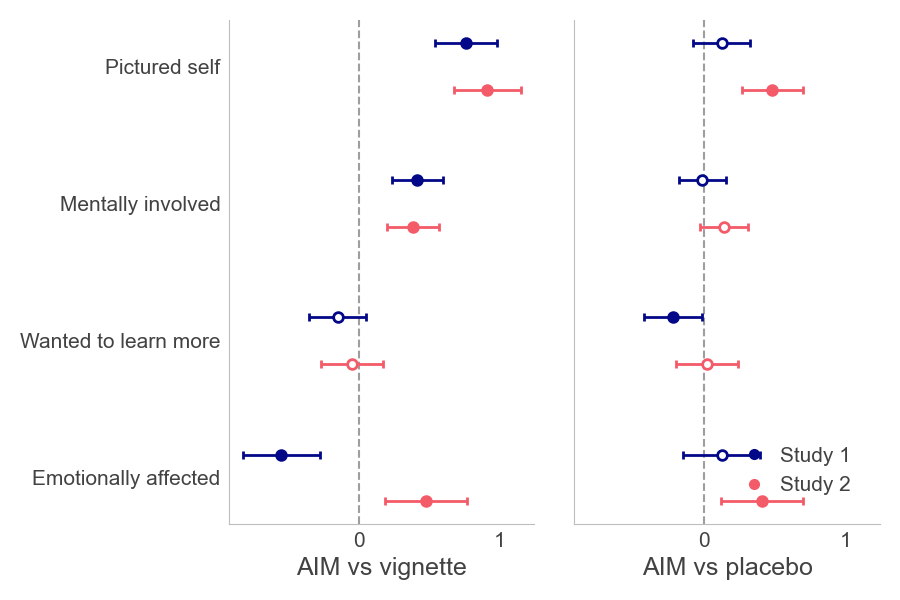

In [12]:
###############
# Figure: item-level treatment effects
###############

make_aesthetic()
fig, axes = plt.subplots(1, 2, figsize=(9, 6), sharex=True)
fig.subplots_adjust(wspace=0.08)
labels = [lab for _, lab in ITEMS]
for ax, ctrl in zip(axes, ["vignette", "placebo"]):
    for yi, lab in enumerate(labels):
        for k, col, off in [("Study 1", "#020887", .17), ("Study 2", "#F45B69", -.17)]:
            r = items[(items.item == lab) & (items.control == ctrl) & (items.study == k)].iloc[0]
            ax.errorbar(r.b, -yi + off, xerr=[[r.b - r.lo], [r.hi - r.b]], fmt="o", markersize=7,
                        capsize=3, linewidth=2, color=col,
                        markerfacecolor=col if r.p < .05 else "white",
                        markeredgecolor=col, markeredgewidth=2)
    ax.axvline(0, color="#9E9E9E", linestyle="--", linewidth=1.5, zorder=0)
    ax.set_yticks(range(0, -len(labels), -1))
    ax.set_yticklabels(labels if ctrl == "vignette" else [])
    ax.set_xlabel(f"AIM vs {ctrl}")
axes[1].legend(handles=[plt.Line2D([], [], color=c, marker="o", linestyle="", markersize=7, label=k)
                        for k, c in [("Study 1", "#020887"), ("Study 2", "#F45B69")]],
               frameon=False, loc="lower right")
fig.savefig(FIGURE_EXPORT / "transportation_items.pdf", bbox_inches="tight", transparent=True)
print("saved plots/transportation_items.pdf")

In [13]:
ITEMS

[('t1_could_pic_self', 'Pictured self'),
 ('t2_mentally_involved', 'Mentally involved'),
 ('t3_wanted_to_learn', 'Wanted to learn more'),
 ('t4_affected_emo', 'Emotionally affected')]

## Driven by the mid-field timer change in Study 2

**Outputs:** `plots/sticky_timer_effects.pdf`, `tables/ruled_out_sticky_timer.tex`

**Computation:** Study 2 was fielded across a change to the writing interface. The countdown timer
became sticky, following the participant down the page instead of scrolling out of view, and that
change reached production on 2026-08-22. Everyone who started on 08-21 ($n=146$) wrote under the
old scrolling timer and everyone after ($n=748$) wrote under the sticky one. We re-estimate the
headline Study 2 effects on the full sample and again after dropping 08-21, using the same
saturated regression the main forest plot uses.

The two samples are nested, so comparing them is not a two-sample test. The formal version fits
`arm x period` on the full sample and asks whether the effect estimated on 08-21 differs from the
effect estimated afterwards. That interaction is the last column of the table.


146
  Outcome  Control \shortstack{All participants\\$b$ [95\% CI]} \shortstack{Excluding 08-21\\$b$ [95\% CI]} \shortstack{Effect $\times$ period\\$b$ [95\% CI]}  $p$
Closeness  Placebo                            0.90 [0.74, 1.05]                           0.86 [0.70, 1.03]                                -0.23 [-0.63, 0.18] .280
Closeness Vignette                            0.38 [0.24, 0.51]                           0.42 [0.27, 0.57]                                 0.20 [-0.16, 0.55] .276
Attitudes  Placebo                            0.67 [0.52, 0.82]                           0.66 [0.49, 0.82]                                -0.09 [-0.45, 0.28] .645
Attitudes Vignette                            0.54 [0.39, 0.69]                           0.55 [0.38, 0.72]                                 0.00 [-0.37, 0.37] .989


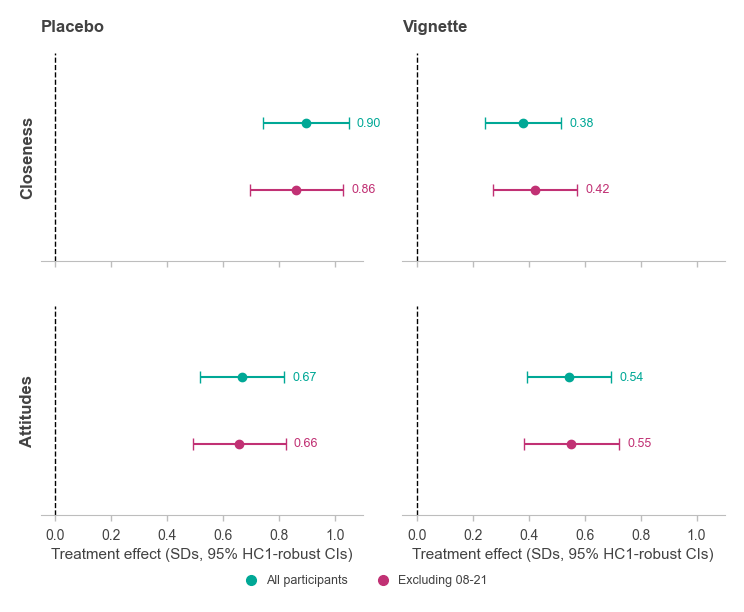

In [14]:
###############
# Ruled out: the mid-field timer change in Study 2
###############
import matplotlib.lines as mlines

SCROLLING_DAY = "08-21"                  # last day before the sticky timer reached production
SAMPLES = {"All participants": lambda d: d,
           "Excluding 08-21": lambda d: d[d.sticky.eq(1)]}
CONTRASTS = {"placebo": "Placebo", "vignette": "Vignette"}      # short: the table says "AIM vs."
TIMER_OUTCOMES = {"closeness_index": "Closeness", "attitude_index": "Attitudes"}
SAMPLE_COLOR = {"All participants": "#00A896", "Excluding 08-21": "#C13174"}

# two-line headers, so a header never sets the column width and the table stays on the page
HEAD_ALL = "\\shortstack{All participants\\\\$b$ [95\\% CI]}"
HEAD_DROP = "\\shortstack{Excluding 08-21\\\\$b$ [95\\% CI]}"
HEAD_TEST = "\\shortstack{Effect $\\times$ period\\\\$b$ [95\\% CI]}"

timer = s2.copy()
# StartDate is UTC and the deploy we are aligning to is Eastern, so shift before taking the day
timer["et"] = pd.to_datetime(timer.StartDate) - pd.Timedelta(hours=4)
timer["sticky"] = (timer.et.dt.strftime("%m-%d") != SCROLLING_DAY).astype(float)
for arm in CONTRASTS:
    timer[f"is_{arm}"] = (timer.treat_status == arm).astype(float)

###############
# Estimation
###############

def aim_advantage(data, outcome, arm):
    """AIM minus the comparison arm. treat is omitted, so we negate the arm coefficient."""
    r = fit(data.dropna(subset=[outcome]), f"{outcome} ~ is_{arm}", f"is_{arm}")
    return {"b": -r["b"], "lo": -r["hi"], "hi": -r["lo"], "p": r["p"], "n": r["n"]}


estimates, rows = [], []
for outcome, outcome_label in TIMER_OUTCOMES.items():
    for arm, contrast_label in CONTRASTS.items():
        pair = timer[timer.treat_status.isin(["treat", arm])]
        by_sample = {}
        for sample_label, select in SAMPLES.items():
            r = aim_advantage(select(pair), outcome, arm)
            by_sample[sample_label] = r
            estimates.append({"outcome": outcome_label, "contrast": contrast_label,
                              "sample": sample_label, **r})
        # nested samples cannot be compared directly; ask instead whether the effect
        # estimated on 08-21 differs from the effect estimated afterwards
        moved = fit(pair, f"{outcome} ~ is_{arm} * sticky", f"is_{arm}:sticky")
        rows.append({"Outcome": outcome_label, "Control": contrast_label,
                     HEAD_ALL: ci_str(**{k: by_sample["All participants"][k]
                                         for k in ("b", "lo", "hi")}),
                     HEAD_DROP: ci_str(**{k: by_sample["Excluding 08-21"][k]
                                          for k in ("b", "lo", "hi")}),
                     HEAD_TEST: ci_str(-moved["b"], -moved["hi"], -moved["lo"]),
                     "$p$": p_str(moved["p"])})

estimates = pd.DataFrame(estimates)

n_dropped = int((timer.sticky == 0).sum())
print(n_dropped)
print(save(rows, "ruled_out_sticky_timer",
      "Sensitivity of the Study 2 effects to the timer change of 2026-08-22, shown on all "
      f"participants and again excluding the {n_dropped} who began before it. Estimates are "
      "AIM-minus-control differences in SDs with HC1 confidence intervals; the last column is the "
      "effect $\\times$ period interaction, the formal test of whether the effect differs across "
      "the change."
      ).to_string(index=False))

###############
# Plot
###############

DODGE = 0.16
pal = make_aesthetic(smallest_font_size=10, with_ticks=True)
plt.rcParams["figure.constrained_layout.use"] = False

fig, axes = plt.subplots(len(TIMER_OUTCOMES), len(CONTRASTS), figsize=(9, 6), sharex=True)
for row, outcome_label in enumerate(TIMER_OUTCOMES.values()):
    for col, contrast_label in enumerate(CONTRASTS.values()):
        ax = axes[row, col]
        panel = estimates[estimates.outcome.eq(outcome_label)
                          & estimates.contrast.eq(contrast_label)]
        for i, (sample_label, _) in enumerate(SAMPLES.items()):
            e = panel[panel["sample"].eq(sample_label)].iloc[0]
            y = DODGE - i * DODGE * 2                 # one row per sample, centred
            ax.errorbar(e.b, y, xerr=[[e.b - e.lo], [e.hi - e.b]], fmt="o",
                        color=SAMPLE_COLOR[sample_label], ecolor=SAMPLE_COLOR[sample_label],
                        capsize=4, markersize=6, linewidth=1.5)
            ax.text(e.hi + 0.03, y, f"{e.b:.2f}", va="center", ha="left", fontsize=9,
                    color=SAMPLE_COLOR[sample_label])
        ax.axvline(0, color="black", linestyle="--", linewidth=1)
        ax.set_yticks([])
        ax.set_ylim(-0.5, 0.5)
        if col == 0:
            ax.set_ylabel(outcome_label, fontsize=12, fontweight="bold")
        if row == 0:
            ax.set_title(contrast_label, fontsize=12, fontweight="bold")
        if row == len(TIMER_OUTCOMES) - 1:
            ax.set_xlabel("Treatment effect (SDs, 95% HC1-robust CIs)", fontsize=11)
        ax.spines[["top", "right", "left"]].set_visible(False)

# n differs by contrast, so it belongs in the table rather than the legend
handles = [mlines.Line2D([], [], color=SAMPLE_COLOR[s], marker="o", linestyle="None",
                         markersize=7, label=s) for s in SAMPLES]
fig.legend(handles=handles, loc="lower center", ncol=2, fontsize=9,
           bbox_to_anchor=(0.5, -0.04), frameon=False)
plt.subplots_adjust(left=0.14, wspace=0.12, hspace=0.22)
plt.savefig(FIGURE_EXPORT / "sticky_timer_effects.pdf", bbox_inches="tight")
plt.show()
